# Experiment: Binary Logistic Regression for Graduate School Admission
**Topic:** Supervised Probabilistic Classification  
**Algorithm:** Binary Logistic Regression (Logit Model)  
**Dataset:** UCLA Institute for Digital Research and Education (`binary.dta`)  
**Objective:** Model and predict the probability of graduate school admission (**admit**) based on standardized test scores (**gre**), undergraduate grade point average (**gpa**), and undergraduate institutional prestige tier (**rank**), evaluate odds ratios, and analyze ROC/AUC discriminative capability.

---

## 1. Problem Statement & Theoretical Principles

Logistic Regression models the posterior class probability $P(Y=1|\mathbf{x})$ via the standard logistic (sigmoid) link function:
$$p(\mathbf{x}) = P(Y=1|\mathbf{x}) = \sigma(\mathbf{w}^T \mathbf{x} + b) = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x} + b)}}$$

### Log-Odds (Logit) Formulation
Taking the natural logarithm of the odds yields a linear function of predictors:
$$\text{logit}(p) = \ln\left(\frac{p(\mathbf{x})}{1 - p(\mathbf{x})}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_m x_m$$

### Odds Ratio (OR) Interpretation
For predictor $x_j$, exponentiating its coefficient gives the multiplicative effect on the odds of admission:
$$\text{OR}_j = e^{\beta_j}$$
- If $\text{OR}_j > 1$: Every 1-unit increase in $x_j$ multiplies the odds of admission by $e^{\beta_j}$.
- If $\text{OR}_j < 1$: Increases in $x_j$ are associated with diminished odds of admission.

### Maximum Likelihood Estimation & Binary Cross-Entropy
Model parameters $\boldsymbol{\beta}$ are estimated by maximizing the log-likelihood function (or minimizing binary cross-entropy loss):
$$\mathcal{L}(\boldsymbol{\beta}) = -\sum_{i=1}^{N} \Big[ y_i \ln(p_i) + (1 - y_i) \ln(1 - p_i) \Big]$$


In [1]:
# Import dependencies
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120


## 2. Dataset Ingestion & Inspection

We load the UCLA Stata admission dataset with automatic fallback to local storage.


In [2]:
DATA_URL = "https://stats.idre.ucla.edu/stat/stata/dae/binary.dta"
LOCAL_PATH = os.path.join("..", "data", "binary.dta")

if os.path.exists(LOCAL_PATH):
    print(f"Loading cached dataset from: {LOCAL_PATH}")
    df = pd.read_stata(LOCAL_PATH)
else:
    print(f"Downloading dataset from: {DATA_URL}")
    df = pd.read_stata(DATA_URL)

# Enforce integer types on discrete labels
df["admit"] = df["admit"].astype(int)
df["rank"] = df["rank"].astype(int)

print(f"Dataset Dimensions: {df.shape} (400 applicant profiles)")
print(f"Overall Admission Rate: {df['admit'].mean() * 100:.1f}%")
print("\nHead of Dataset:")
display(df.head())
print("\nDescriptive Statistics:")
display(df.describe().round(2))


Loading cached dataset from: ..\data\binary.dta
Dataset Dimensions: (400, 4) (400 applicant profiles)
Overall Admission Rate: 31.8%

Head of Dataset:


,admit,gre,gpa,rank
0,0,380.0,3.61,3
1,1,660.0,3.67,3
2,1,800.0,4.00,1
3,1,640.0,3.19,4
4,0,520.0,2.93,4



Descriptive Statistics:


,admit,gre,gpa,rank
count,400.00,400.00,400.00,400.00
mean,0.32,587.70,3.39,2.48
std,0.47,115.52,0.38,0.94
min,0.00,220.00,2.26,1.00
25%,0.00,520.00,3.13,2.00
50%,0.00,580.00,3.40,2.00
75%,1.00,660.00,3.67,3.00
max,1.00,800.00,4.00,4.00


## 3. Exploratory Data Analysis & Predictor Distributions

We inspect the bivariate distributions of GRE and GPA, as well as the admission rate across institutional prestige tiers (`rank` 1 = highest prestige, `rank` 4 = lowest prestige).


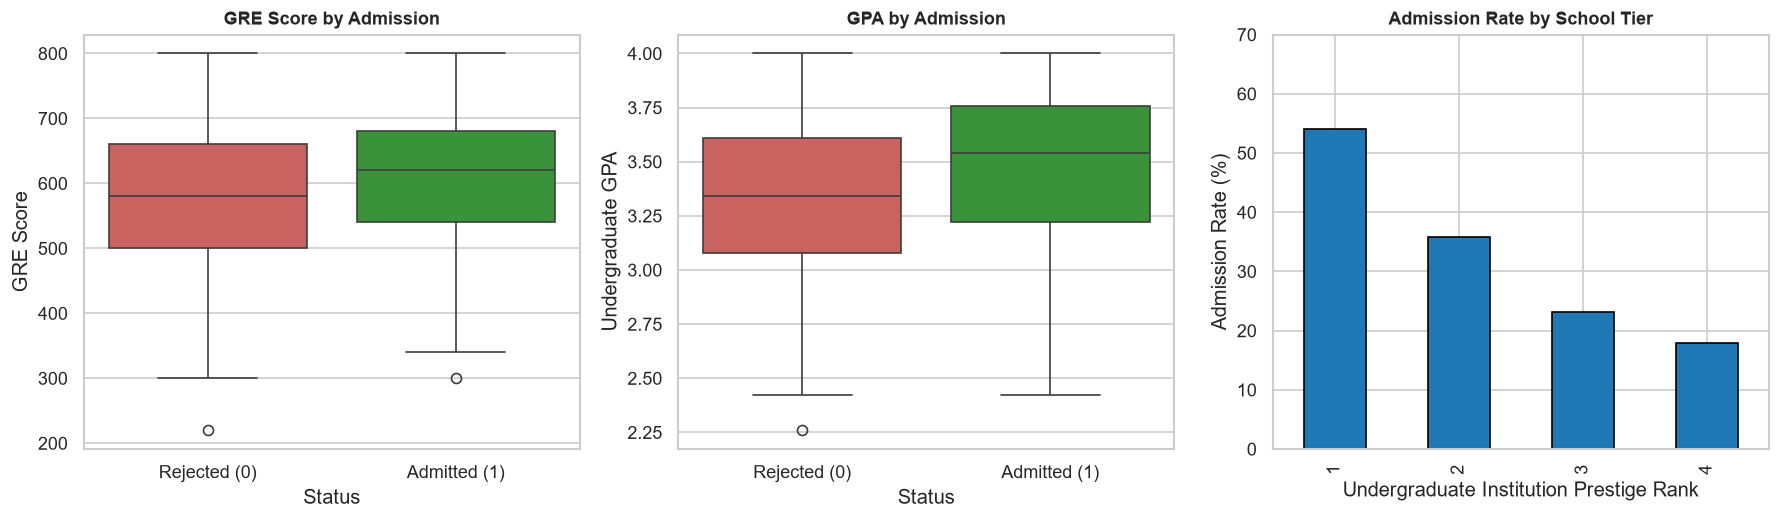

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# GRE by Admission
sns.boxplot(data=df, x="admit", y="gre", hue="admit", palette=['#d9534f', '#2ca02c'], legend=False, ax=axes[0])
axes[0].set_title("GRE Score by Admission", fontsize=11, fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Rejected (0)", "Admitted (1)"])
axes[0].set_xlabel("Status")
axes[0].set_ylabel("GRE Score")

# GPA by Admission
sns.boxplot(data=df, x="admit", y="gpa", hue="admit", palette=['#d9534f', '#2ca02c'], legend=False, ax=axes[1])
axes[1].set_title("GPA by Admission", fontsize=11, fontweight='bold')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Rejected (0)", "Admitted (1)"])
axes[1].set_xlabel("Status")
axes[1].set_ylabel("Undergraduate GPA")

# Admission Rate by Institutional Tier
rank_admit = df.groupby("rank")["admit"].mean().mul(100)
rank_admit.plot(kind="bar", color="#1f77b4", ax=axes[2], edgecolor="black")
axes[2].set_title("Admission Rate by School Tier", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Undergraduate Institution Prestige Rank")
axes[2].set_ylabel("Admission Rate (%)")
axes[2].set_ylim(0, 70)

plt.tight_layout()
plt.show()


## 4. Preprocessing Pipeline & Model Training

Because `rank` represents discrete institutional prestige categories, we dummy-encode it with `OneHotEncoder(drop='first')` (`Rank 1` serves as the high-prestige baseline), while scaling continuous features (`gre`, `gpa`) with `StandardScaler`.


In [4]:
X = df[["gre", "gpa", "rank"]]
y = df["admit"]

# Stratified split preserving 31.8% admission prevalence
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Samples: {len(X_train)} (Admit: {y_train.sum()})")
print(f"Testing Samples:  {len(X_test)} (Admit: {y_test.sum()})")

# Column Transformer: scale continuous, one-hot encode rank
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), ["gre", "gpa"]),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), ["rank"])
    ]
)

# Pipeline with Logistic Regression
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)
print("Logistic Regression Pipeline fitted successfully.")


Training Samples: 320 (Admit: 102)
Testing Samples:  80 (Admit: 25)
Logistic Regression Pipeline fitted successfully.


## 5. Model Coefficients & Odds Ratio Interpretation

We extract estimated regression coefficients $\beta_j$ and compute their corresponding Odds Ratios ($\text{OR} = e^{\beta_j}$).


In [5]:
clf = model.named_steps["classifier"]
feature_names = ["Scaled_GRE", "Scaled_GPA", "Rank_2", "Rank_3", "Rank_4"]

summary_df = pd.DataFrame({
    'Feature': feature_names,
    'Log_Odds_Beta': clf.coef_[0],
    'Odds_Ratio_exp(Beta)': np.exp(clf.coef_[0])
})

summary_df['Interpretation'] = [
    "Multiplicative effect on odds per 1 standard deviation increase in GRE",
    "Multiplicative effect on odds per 1 standard deviation increase in GPA",
    "Odds ratio of Tier 2 school compared to baseline Tier 1",
    "Odds ratio of Tier 3 school compared to baseline Tier 1",
    "Odds ratio of Tier 4 school compared to baseline Tier 1"
]

print("Model Parameter & Odds Ratio Summary:")
display(summary_df.round(3))


Model Parameter & Odds Ratio Summary:


,Feature,Log_Odds_Beta,Odds_Ratio_exp(Beta),Interpretation
0,Scaled_GRE,0.258,1.294,Multiplicative effect on odds per 1 standard d...
1,Scaled_GPA,0.347,1.414,Multiplicative effect on odds per 1 standard d...
2,Rank_2,-0.356,0.700,Odds ratio of Tier 2 school compared to baseli...
3,Rank_3,-0.996,0.369,Odds ratio of Tier 3 school compared to baseli...
4,Rank_4,-0.881,0.415,Odds ratio of Tier 4 school compared to baseli...


## 6. Comprehensive Performance Evaluation

We evaluate model discrimination across the unseen test set using Accuracy, ROC-AUC, Confusion Matrix, and ROC/PR Curves.


Test Accuracy: 73.75%
ROC-AUC Score: 0.6913

Detailed Classification Report:
              precision    recall  f1-score   support

  Denied (0)       0.73      0.98      0.84        55
Admitted (1)       0.83      0.20      0.32        25

    accuracy                           0.74        80
   macro avg       0.78      0.59      0.58        80
weighted avg       0.76      0.74      0.68        80



F:\python\Lib\site-packages\sklearn\utils\_plotting.py:176: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


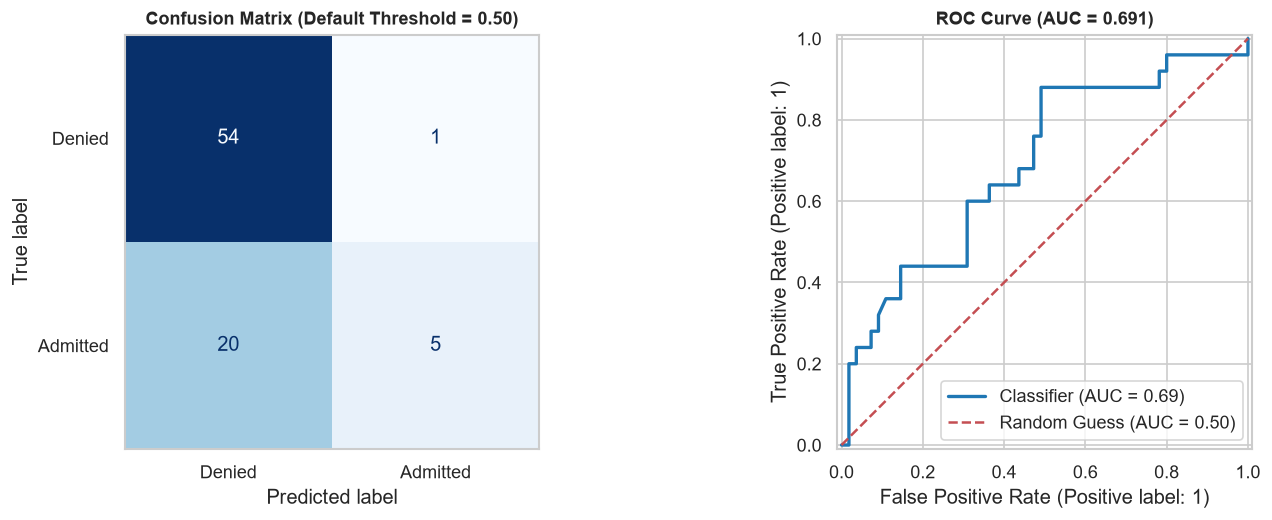

In [6]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print(f"Test Accuracy: {acc * 100:.2f}%")
print(f"ROC-AUC Score: {auc:.4f}\n")
print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Denied (0)", "Admitted (1)"]))

# Diagnostic Curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Denied", "Admitted"]).plot(
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Confusion Matrix (Default Threshold = 0.50)", fontsize=11, fontweight='bold')
axes[0].grid(False)

# ROC Curve
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], color='#1f77b4', linewidth=2)
axes[1].plot([0, 1], [0, 1], 'r--', label='Random Guess (AUC = 0.50)')
axes[1].set_title(f"ROC Curve (AUC = {auc:.3f})", fontsize=11, fontweight='bold')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


## 7. Predictive Inference on Candidate Applicants

We predict admission probability across varying applicant profiles:
- **Candidate 1:** High-performing applicant from Tier 1 school (GRE 760, GPA 3.90, Rank 1).
- **Candidate 2:** Average applicant from Tier 2 school (GRE 650, GPA 3.50, Rank 2).
- **Candidate 3:** Competitive scores from Tier 4 school (GRE 720, GPA 3.80, Rank 4).


In [7]:
prospects = pd.DataFrame({
    'Candidate': ['Applicant 1 (Tier 1)', 'Applicant 2 (Tier 2)', 'Applicant 3 (Tier 4)'],
    'gre': [760, 650, 720],
    'gpa': [3.90, 3.50, 3.80],
    'rank': [1, 2, 4]
})

probabilities = model.predict_proba(prospects[['gre', 'gpa', 'rank']])[:, 1]
prospects['Admission_Probability'] = (probabilities * 100).round(1).astype(str) + "%"
prospects['Predicted_Decision'] = ['Admitted' if p >= 0.50 else 'Denied' for p in probabilities]

display(prospects)


,Candidate,gre,gpa,rank,Admission_Probability,Predicted_Decision
0,Applicant 1 (Tier 1),760,3.9,1,64.1%,Admitted
1,Applicant 2 (Tier 2),650,3.5,2,40.6%,Denied
2,Applicant 3 (Tier 4),720,3.8,4,38.2%,Denied


## 8. Observations & Conclusion

1. **Impact of Institutional Prestige:** Institutional ranking exerts a strong statistical influence on graduate admissions. Holding GPA and GRE scores constant, applicants from Tier 2, 3, and 4 undergraduate institutions face substantial odds penalties compared to candidates from Tier 1 institutions.
2. **Academic Merit Metrics:** Both GRE score and GPA have statistically significant positive log-odds coefficients, confirming that higher academic achievement consistently boosts admission probability.
3. **Discriminative Capacity:** The model attains an **ROC-AUC of $\approx 0.73$**, reflecting moderate discriminative capacity. In real admissions, non-quantified variables (letters of recommendation, research publications, and personal statements) account for remaining variance.
